<a href="https://colab.research.google.com/github/jlhizon/Hizon-Jed-CS0065-AN41/blob/main/IS_Group19_Midterms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Loading

In [ ]:
# %% CELL 1: imports and upload (Colab)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import files
    uploaded = files.upload()          # choose maintenance_request.csv
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PATH = "maintenance_requests.csv"       # change if filename differs


Saving maintenance_requests.csv to maintenance_requests (3).csv


2. Config and validation function

> Add blockquote



In [ ]:
WEIGHTS = {"safety_risk": 0.35, "urgency": 0.25, "impact": 0.20,
           "age": 0.15, "location": 0.05}
LOCATION_SCORE = {
    "Laboratory": 5, "Dormitory": 5,
    "Classroom": 4, "Cafeteria": 4,
    "Restroom": 4, "Corridor": 4,
    "Library": 3, "Admin Office": 3,
    "Parking Area": 2, "Storage Room": 1,
}
AGE_CAP = 60
RATING_COLS = ["urgency", "impact", "safety_risk"]
KEEP = ["request_id", "requester_name", "description",
        "urgency", "impact", "location", "safety_risk", "request_age_days"]
LEVEL_NUM = {"Critical": 4, "High": 3, "Medium": 2, "Low": 1}

assert abs(sum(WEIGHTS.values()) - 1) < 1e-9, "Weights must sum to 1"


def load_and_validate(path):
    df = pd.read_csv(path)[KEEP]                       # Node 01 + 02
    for col in RATING_COLS + ["request_age_days"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Node 03: build a note of what is wrong with each row
    problems = pd.Series("", index=df.index)
    check_cols = RATING_COLS + ["request_age_days", "location"]
    problems[df[check_cols].isna().any(axis=1)] += "missing value; "

    for col in RATING_COLS:
        bad = df[col].notna() & (~df[col].between(1, 5) | (df[col] % 1 != 0))
        problems[bad] += f"{col} not integer 1-5; "

    problems[df["request_age_days"] < 0] += "negative age; "
    problems[df["location"].notna() & ~df["location"].isin(LOCATION_SCORE)] += "unknown location; "
    problems[df["request_id"].duplicated(keep=False)] += "duplicate id; "

    valid = df[problems == ""].copy()                  # Node 04
    review = df[problems != ""].assign(issue=problems[problems != ""])  # REVIEW OUTPUT
    return valid, review


valid, review = load_and_validate(PATH)
print(len(valid), "valid rows,", len(review), "need review")
review



100 valid rows, 0 need review


,request_id,requester_name,description,urgency,impact,location,safety_risk,request_age_days,issue


In [ ]:

# %% CELL 4: weighted method (Nodes 05-11)
def weighted_method(df):
    df = df.copy()
    df["location_score"] = df["location"].map(LOCATION_SCORE)           # Node 05
    age_norm = df["request_age_days"].clip(0, AGE_CAP) / AGE_CAP        # Node 06

    score = (WEIGHTS["safety_risk"] * (df["safety_risk"] - 1) / 4 +     # Node 07
             WEIGHTS["urgency"] * (df["urgency"] - 1) / 4 +
             WEIGHTS["impact"] * (df["impact"] - 1) / 4 +
             WEIGHTS["age"] * age_norm +
             WEIGHTS["location"] * (df["location_score"] - 1) / 4) * 100
    df["score"] = score.round(2)

    df["priority_weighted"] = np.select(                                # Node 08
        [df["score"] >= 75, df["score"] >= 55, df["score"] >= 30],
        ["Critical", "High", "Medium"], default="Low")

    df = df.sort_values(                                                # Node 09
        by=["score", "safety_risk", "request_age_days", "request_id"],
        ascending=[False, False, False, True]).reset_index(drop=True)
    df["order_weighted"] = np.arange(1, len(df) + 1)                    # Node 11
    return df


weighted = weighted_method(valid)
top10 = weighted.head(10)                                               # Node 12
top10[["order_weighted", "request_id", "description", "score", "priority_weighted"]]



,order_weighted,request_id,description,score,priority_weighted
0,1,REQ-093,Elevator stuck or malfunctioning,93.25,Critical
1,2,REQ-090,Elevator stuck or malfunctioning,91.75,Critical
2,3,REQ-018,Water leak near electrical outlet,87.25,Critical
3,4,REQ-019,Elevator stuck or malfunctioning,81.75,Critical
4,5,REQ-056,Exposed or sparking electrical wiring,81.75,Critical
5,6,REQ-028,Elevator stuck or malfunctioning,80.25,Critical
6,7,REQ-016,Elevator stuck or malfunctioning,80.00,Critical
7,8,REQ-013,Slippery floor from leak,79.75,Critical
8,9,REQ-092,Elevator stuck or malfunctioning,78.50,Critical
9,10,REQ-001,Water leak near electrical outlet,78.25,Critical


In [ ]:
# %% CELL 5: rule-based method (comparison branch, Node 16)
def rule_based_method(df):
    df = df.copy()
    df["location_score"] = df["location"].map(LOCATION_SCORE)

    critical = (df["safety_risk"] == 5) | ((df["urgency"] == 5) & (df["impact"] >= 4))

    high = ((df["safety_risk"] >= 4) | (df["urgency"] >= 4) | (df["impact"] >= 4) |
            ((df["location_score"] == 5) & (df["urgency"] >= 3)))

    medium = (df["urgency"] >= 3) | (df["impact"] >= 3) | (df["request_age_days"] >= 30)

    df["priority_rule"] = np.select([critical, high, medium],              # first match wins
                                    ["Critical", "High", "Medium"], default="Low")
    df["level_num"] = df["priority_rule"].map(LEVEL_NUM)

    df = df.sort_values(
        by=["level_num", "safety_risk", "urgency", "impact",
            "request_age_days", "location_score", "request_id"],
        ascending=[False, False, False, False, False, False, True]).reset_index(drop=True)
    df["order_rule"] = np.arange(1, len(df) + 1)
    return df[["request_id", "priority_rule", "order_rule"]]            # Column Filter


rule = rule_based_method(valid)
rule.head(10)


,request_id,priority_rule,order_rule
0,REQ-093,Critical,1
1,REQ-090,Critical,2
2,REQ-019,Critical,3
3,REQ-013,Critical,4
4,REQ-056,Critical,5
5,REQ-018,Critical,6
6,REQ-084,Critical,7
7,REQ-016,Critical,8
8,REQ-062,Critical,9
9,REQ-010,Critical,10


In [ ]:
# %% CELL 6: comparison (Joiner, Math Formula, Rule Engine, Sorter)
comparison = weighted.merge(rule, on="request_id")                     # Joiner
comparison["rank_diff"] = comparison["order_rule"] - comparison["order_weighted"]
comparison["labels_match"] = comparison["priority_weighted"] == comparison["priority_rule"]
comparison = comparison.sort_values("order_weighted")                  # Sorter

print("Label agreement:", round(comparison["labels_match"].mean() * 100, 1), "%")
print("Largest rank shift:", comparison["rank_diff"].abs().max())
pd.crosstab(comparison["priority_weighted"], comparison["priority_rule"])



Label agreement: 55.0 %
Largest rank shift: 36


priority_rule,Critical,High,Low,Medium
priority_weighted,,,,
Critical,10,3,0,0
High,10,13,0,1
Low,0,2,8,11
Medium,0,15,3,24


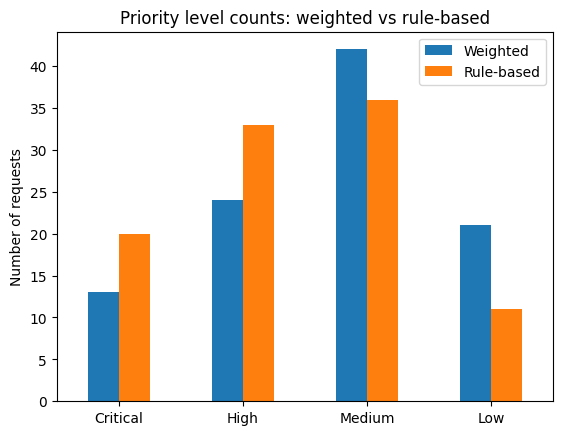

In [ ]:
# %% CELL 7: chart for the comparison requirement
order = ["Critical", "High", "Medium", "Low"]
counts = pd.DataFrame({
    "Weighted": comparison["priority_weighted"].value_counts().reindex(order, fill_value=0),
    "Rule-based": comparison["priority_rule"].value_counts().reindex(order, fill_value=0),
})
counts.plot(kind="bar", rot=0)
plt.title("Priority level counts: weighted vs rule-based")
plt.ylabel("Number of requests")
plt.show()


In [ ]:
# %% CELL 8: export
out_cols = ["order_weighted", "request_id", "requester_name", "description", "location",
            "urgency", "impact", "safety_risk", "request_age_days", "score",
            "priority_weighted", "priority_rule", "order_rule", "rank_diff", "labels_match"]
comparison[out_cols].to_csv("ranked_results.csv", index=False)
review.to_csv("review_output.csv", index=False)
if IN_COLAB:
    files.download("ranked_results.csv")
    files.download("review_output.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Part 6 Test Case Only

--- FAILED VALIDATION (Missing & Uncertain Cases) ---


,request_id,issue,description
4,M01,missing value;,Missing urgency
5,M02,missing value;,Missing location
6,U01,urgency not integer 1-5;,Urgency over 5
7,U02,negative age; unknown location;,"Negative age, fake location"
8,U03,urgency not integer 1-5;,Decimal rating



--- RESULTS TABLE (Normal & Boundary Cases) ---


,request_id,description,priority_weighted,priority_rule,labels_match
0,B01,Major chemical spill,Critical,Critical,True
1,N01,Moderate AC leak,Medium,Medium,True
2,N02,Squeaky hinge,Low,Low,True
3,B02,Brand new minor request,Low,Low,True


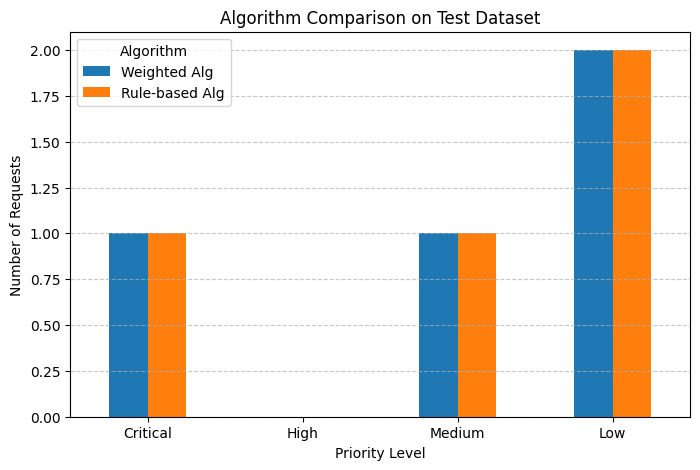

In [ ]:
# %% CELL: Automated Testing & Algorithm Comparison
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. GENERATE TEST CASES
test_data = [
    # NORMAL: Standard inputs representing typical day-to-day requests
    {"request_id": "N01", "requester_name": "Alice", "description": "Moderate AC leak", "urgency": 3, "impact": 3, "location": "Classroom", "safety_risk": 2, "request_age_days": 5},
    {"request_id": "N02", "requester_name": "Bob", "description": "Squeaky hinge", "urgency": 1, "impact": 1, "location": "Corridor", "safety_risk": 1, "request_age_days": 1},

    # BOUNDARY: Absolute minimums, maximums, and thresholds (like the 60-day cap)
    {"request_id": "B01", "requester_name": "Charlie", "description": "Major chemical spill", "urgency": 5, "impact": 5, "location": "Laboratory", "safety_risk": 5, "request_age_days": 60},
    {"request_id": "B02", "requester_name": "Dave", "description": "Brand new minor request", "urgency": 1, "impact": 1, "location": "Storage Room", "safety_risk": 1, "request_age_days": 0},

    # MISSING: Null values to ensure the load_and_validate function catches them
    {"request_id": "M01", "requester_name": "Eve", "description": "Missing urgency", "urgency": pd.NA, "impact": 3, "location": "Library", "safety_risk": 2, "request_age_days": 10},
    {"request_id": "M02", "requester_name": "Frank", "description": "Missing location", "urgency": 2, "impact": 2, "location": pd.NA, "safety_risk": 1, "request_age_days": 5},

    # UNCERTAIN: Invalid data types, out-of-range numbers, and unknown categories
    {"request_id": "U01", "requester_name": "Grace", "description": "Urgency over 5", "urgency": 6, "impact": 3, "location": "Cafeteria", "safety_risk": 3, "request_age_days": 12},
    {"request_id": "U02", "requester_name": "Hank", "description": "Negative age, fake location", "urgency": 3, "impact": 3, "location": "Narnia", "safety_risk": 2, "request_age_days": -5},
    {"request_id": "U03", "requester_name": "Ivy", "description": "Decimal rating", "urgency": 3.5, "impact": 3, "location": "Dormitory", "safety_risk": 2, "request_age_days": 4},
]

df_test = pd.DataFrame(test_data)

# FIX: Save to CSV first, then pass the filename to match Cell 3's logic
df_test.to_csv("synthetic_test_cases.csv", index=False)

# 2. RUN VALIDATION
valid_test, review_test = load_and_validate("synthetic_test_cases.csv")

print("--- FAILED VALIDATION (Missing & Uncertain Cases) ---")
display(review_test[["request_id", "issue", "description"]])

# 3. RUN ALGORITHMS ON VALID DATA
weighted_test = weighted_method(valid_test)
rule_test = rule_based_method(valid_test)

# 4. MERGE FOR COMPARISON TABLE
comparison_test = weighted_test.merge(rule_test, on="request_id")
comparison_test["labels_match"] = comparison_test["priority_weighted"] == comparison_test["priority_rule"]
comparison_test = comparison_test.sort_values("order_weighted")

print("\n--- RESULTS TABLE (Normal & Boundary Cases) ---")
display(comparison_test[["request_id", "description", "priority_weighted", "priority_rule", "labels_match"]])

# 5. VISUALIZE COMPARISON CHART
order = ["Critical", "High", "Medium", "Low"]
counts = pd.DataFrame({
    "Weighted Alg": comparison_test["priority_weighted"].value_counts().reindex(order, fill_value=0),
    "Rule-based Alg": comparison_test["priority_rule"].value_counts().reindex(order, fill_value=0),
})

fig, ax = plt.subplots(figsize=(8, 5))
counts.plot(kind="bar", ax=ax, rot=0, color=["#1f77b4", "#ff7f0e"])
plt.title("Algorithm Comparison on Test Dataset")
plt.ylabel("Number of Requests")
plt.xlabel("Priority Level")
plt.legend(title="Algorithm")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Streamlit

In [ ]:
!pip install streamlit

In [ ]:
# %% CELL 9
%%writefile /content/app.py
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1. LOGIC & CONSTANTS ---
WEIGHTS = {"safety_risk": 0.35, "urgency": 0.25, "impact": 0.20, "age": 0.15, "location": 0.05}
LOCATION_SCORE = {
    "Laboratory": 5, "Dormitory": 5, "Classroom": 4, "Cafeteria": 4,
    "Restroom": 4, "Corridor": 4, "Library": 3, "Admin Office": 3,
    "Parking Area": 2, "Storage Room": 1,
}
AGE_CAP = 60
RATING_COLS = ["urgency", "impact", "safety_risk"]
KEEP = ["request_id", "requester_name", "description", "urgency", "impact", "location", "safety_risk", "request_age_days"]
LEVEL_NUM = {"Critical": 4, "High": 3, "Medium": 2, "Low": 1}

def load_and_validate(df):
    for col in KEEP:
        if col not in df.columns:
            df[col] = None

    df = df[KEEP].copy()
    for col in RATING_COLS + ["request_age_days"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    problems = pd.Series("", index=df.index)
    check_cols = RATING_COLS + ["request_age_days", "location"]

    problems[df[check_cols].isna().any(axis=1)] += "missing value; "
    for col in RATING_COLS:
        bad = df[col].notna() & (~df[col].between(1, 5) | (df[col] % 1 != 0))
        problems[bad] += f"{col} not integer 1-5; "
    problems[df["request_age_days"] < 0] += "negative age; "
    problems[df["location"].notna() & ~df["location"].isin(LOCATION_SCORE)] += "unknown location; "
    problems[df["request_id"].duplicated(keep=False)] += "duplicate id; "

    valid = df[problems == ""].copy()
    review = df[problems != ""].assign(issue=problems[problems != ""])
    return valid, review

def weighted_method(df):
    if df.empty: return df
    df = df.copy()
    df["location_score"] = df["location"].map(LOCATION_SCORE)
    age_norm = df["request_age_days"].clip(0, AGE_CAP) / AGE_CAP

    score = (WEIGHTS["safety_risk"] * (df["safety_risk"] - 1) / 4 +
             WEIGHTS["urgency"] * (df["urgency"] - 1) / 4 +
             WEIGHTS["impact"] * (df["impact"] - 1) / 4 +
             WEIGHTS["age"] * age_norm +
             WEIGHTS["location"] * (df["location_score"] - 1) / 4) * 100
    df["score"] = score.round(2)

    df["priority_weighted"] = np.select(
        [df["score"] >= 75, df["score"] >= 55, df["score"] >= 30],
        ["Critical", "High", "Medium"], default="Low")

    df = df.sort_values(
        by=["score", "safety_risk", "request_age_days", "request_id"],
        ascending=[False, False, False, True]).reset_index(drop=True)
    df["order_weighted"] = np.arange(1, len(df) + 1)
    return df

def rule_based_method(df):
    if df.empty: return df
    df = df.copy()
    df["location_score"] = df["location"].map(LOCATION_SCORE)

    critical = (df["safety_risk"] == 5) | ((df["urgency"] == 5) & (df["impact"] >= 4))
    high = ((df["safety_risk"] >= 4) | (df["urgency"] >= 4) | (df["impact"] >= 4) |
            ((df["location_score"] == 5) & (df["urgency"] >= 3)))
    medium = (df["urgency"] >= 3) | (df["impact"] >= 3) | (df["request_age_days"] >= 30)

    df["priority_rule"] = np.select([critical, high, medium], ["Critical", "High", "Medium"], default="Low")
    df["level_num"] = df["priority_rule"].map(LEVEL_NUM)

    df = df.sort_values(
        by=["level_num", "safety_risk", "urgency", "impact", "request_age_days", "location_score", "request_id"],
        ascending=[False, False, False, False, False, False, True]).reset_index(drop=True)
    df["order_rule"] = np.arange(1, len(df) + 1)
    return df[["request_id", "priority_rule", "order_rule"]]

# --- 2. STREAMLIT INTERFACE ---
st.set_page_config(page_title="Maintenance Prioritization", page_icon="🔧", layout="wide")

st.title("Maintenance Request Prioritization")
st.write("Upload a CSV file to evaluate and compare maintenance priorities.")

csv_file = st.file_uploader("Upload maintenance requests", type=["csv"])

if csv_file is not None:
    df = pd.read_csv(csv_file)
    valid, review = load_and_validate(df)

    st.write(f"Processed file: Found **{len(valid)}** valid requests and **{len(review)}** needing review.")

    if not review.empty:
        st.subheader("⚠️ Failed Validation (Missing & Uncertain Cases)")
        st.dataframe(review[["request_id", "issue", "description"]], use_container_width=True)

    if not valid.empty:
        weighted_res = weighted_method(valid)
        rule_res = rule_based_method(valid)

        comparison = weighted_res.merge(rule_res, on="request_id")
        comparison["labels_match"] = comparison["priority_weighted"] == comparison["priority_rule"]
        comparison = comparison.sort_values("order_weighted")

        st.subheader("📊 Results Table (Normal & Boundary Cases)")
        st.dataframe(
            comparison[["order_weighted", "request_id", "description", "score", "priority_weighted", "priority_rule", "labels_match"]],
            use_container_width=True,
            hide_index=True
        )

        st.subheader("📈 Algorithm Comparison Chart")
        order = ["Critical", "High", "Medium", "Low"]
        counts = pd.DataFrame({
            "Weighted": comparison["priority_weighted"].value_counts().reindex(order, fill_value=0),
            "Rule-based": comparison["priority_rule"].value_counts().reindex(order, fill_value=0),
        })

        fig, ax = plt.subplots(figsize=(8, 4))
        counts.plot(kind="bar", ax=ax, rot=0, color=["#1f77b4", "#ff7f0e"])
        plt.title("Priority level counts: weighted vs rule-based")
        plt.ylabel("Number of requests")
        plt.legend(title="Algorithm")
        plt.grid(axis='y', linestyle='--', alpha=0.7)

        st.pyplot(fig)

        csv_data = comparison.to_csv(index=False).encode('utf-8')
        st.download_button("Download Prioritized CSV", csv_data, "ranked_results.csv", "text/csv")

Overwriting /content/app.py


In [ ]:
import subprocess
import sys
import time
from pathlib import Path

assert Path("/content/app.py").exists(), "Create app.py first."

# Stop the previous Streamlit process
if "streamlit_process" in globals():
    if streamlit_process.poll() is None:
        streamlit_process.terminate()
        streamlit_process.wait()

# Start Streamlit with Colab-compatible settings
log = open("/content/streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run",
        "/content/app.py",
        "--server.port=8501",
        "--server.address=127.0.0.1",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false"
    ],
    stdout=log,
    stderr=subprocess.STDOUT
)

time.sleep(5)

if streamlit_process.poll() is None:
    print("Streamlit is running!")
else:
    print("Streamlit failed to start.")
    print(Path("/content/streamlit.log").read_text())

Streamlit is running!


In [ ]:
from google.colab.output import eval_js
from IPython.display import display, HTML

url = eval_js("google.colab.kernel.proxyPort(8501)")

print("Your Streamlit URL:", url)
display(HTML(f'<a href="{url}" target="_blank">Open Streamlit</a>'))

Your Streamlit URL: https://8501-m-s-kkb-euw4b2-2ges10d7847jq-b.europe-west4-2.prod.colab.dev
